# Métodos de la revisión de literatura

Explicaciones **conceptuales** de los métodos que aparecen en los artículos de mi revisión de literatura. El objetivo es tener claro el concepto de cada método, no un tratamiento exhaustivo.

Los métodos están organizados **por función**: cada función es una sección de nivel 1 y cada método una subsección dentro de ella. Cada método se explica como una narrativa corta: para qué sirve → idea central (fórmula y gráfica) → requisitos o limitación principal → aplicación a puentes → tabla de fortalezas y debilidades. El texto está en español; el código, en inglés.

## Tabla de contenido

| Función | Método |
|---|---|
| [0. Fundamentos: señal, forma modal y amplitud](#fundamentos) | Concepto base (no es un método) |
| [1. Descomposición de señales](#descomposicion-de-senales) | [1.1 EMD (Empirical Mode Decomposition)](#emd) |
| [2. Envolvente de amplitud / amplitud instantánea](#envolvente-de-amplitud) | [2.1 Transformada de Hilbert](#transformada-de-hilbert) |
| [3. Sensado disperso](#sensado-disperso) | [3.1 Mapeo a puntos fijos virtuales](#mapeo-vfp) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, sosfiltfilt, argrelextrema
from scipy.interpolate import CubicSpline
from PyEMD import EMD

# Shared plot style: thin lines, recessive grid, no top/right spines
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e3e2de",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 1.4,
    "legend.frameon": False,
})

# Fixed color roles (same meaning in every plot)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # main series (blue)
COLOR_2 = "#eb6834"        # second series (orange)
COLOR_TRUE = "#0b0b0b"     # exact (true) reference curve, dashed

# --- Shared example: vehicle crossing a simply supported bridge ---
L_SPAN = 15.0         # span (m)
V_SPEED = 2.0         # vehicle speed (m/s)
F1, F2 = 5.65, 22.62  # bridge natural frequencies (Hz)
FS = 200.0            # sampling frequency (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # vehicle position x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # mode 1 shape
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # mode 2 shape

<a id="fundamentos"></a>
# 0. Fundamentos: señal, forma modal y amplitud

Concepto base que necesitan los métodos siguientes: qué mide un sensor en un puente, por qué la **proporción** entre puntos es la forma modal y por qué hay que aislar un solo modo para recuperarla.

### Qué mide un sensor en el puente

La vibración del puente se escribe como una suma de modos:

$$
y(x,t) = \sum_n \phi_n(x)\,q_n(t)
$$

- $y(x,t)$: desplazamiento vertical del puente en la posición $x$ y el instante $t$.
- $\phi_n(x)$: forma del modo $n$; es fija y no cambia en el tiempo.
- $q_n(t)$: coordenada modal, es decir, cuánto está activado el modo $n$ en el instante $t$; es un solo número para todo el puente.

En palabras: en cada instante, la deformada del puente es la suma de unas pocas formas fijas, cada una multiplicada por su "tamaño" en ese instante.

**De dónde sale.** Se resuelve la ecuación de movimiento $M\ddot{y} + Ky = 0$ por separación de variables ($y = \phi\,q$). La parte espacial, $(K - \omega^2 M)\phi = 0$, da las formas $\phi_n$ y las frecuencias $\omega_n$; la parte temporal da $q_n(t)$, un oscilador a la frecuencia del modo. Aquí $K$ es la rigidez, $M$ la masa y $\omega = 2\pi f$ la frecuencia natural circular (rad/s).

**Lo que mide el sensor.** Un acelerómetro mide la aceleración, $\ddot{y}(x,t) = \sum_n \phi_n(x)\,\ddot{q}_n(t)$, con la misma forma $\phi_n(x)$: derivar en el tiempo solo afecta a $q_n(t)$.

### Un solo modo: la forma no cambia, solo su tamaño

Con un solo modo, $y(x,t) = \phi(x)\,q(t)$. Para el modo 1 de la viga simplemente apoyada, $\phi(x) = \sin(\pi x / L)$. Izquierda: la forma dibujada en varios instantes de un ciclo ($q$ = 1, 0.5, 0, −0.5, −1). Derecha: el desplazamiento en dos puntos ($x$ = 3 m y 7.5 m) con una vibración amortiguada.

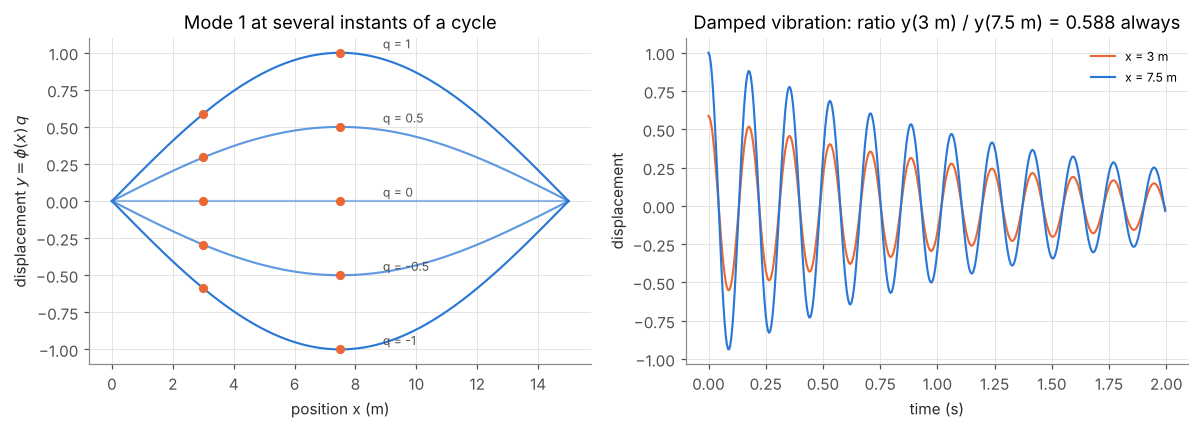

In [2]:
x_grid = np.linspace(0, L_SPAN, 301)
shape_1 = np.sin(np.pi * x_grid / L_SPAN)          # phi(x), mode 1
x_a, x_b = 3.0, 7.5                                 # two points on the deck (m)
phi_a, phi_b = np.sin(np.pi * x_a / L_SPAN), np.sin(np.pi * x_b / L_SPAN)

# Damped modal coordinate q(t) (2 % damping)
t_free = np.arange(0, 2, 1 / FS)
q_free = np.exp(-0.02 * 2 * np.pi * F1 * t_free) * np.cos(2 * np.pi * F1 * t_free)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
for q, alpha in zip([1, 0.5, 0, -0.5, -1], [1, 0.75, 0.5, 0.75, 1]):
    ax.plot(x_grid, q * shape_1, color=COLOR_1, alpha=alpha, linewidth=1.4)
    ax.plot([x_a, x_b], [q * phi_a, q * phi_b], "o", ms=5, color=COLOR_2)
    ax.annotate(f"q = {q:g}", xy=(L_SPAN / 2, q), xytext=(L_SPAN / 2 + 1.4, q + 0.06), fontsize=8,
                va="center", color="#52514e")
ax.set_xlabel("position x (m)")
ax.set_ylabel(r"displacement $y = \phi(x)\,q$")
ax.set_title("Mode 1 at several instants of a cycle")

ax = axes[1]
ax.plot(t_free, phi_a * q_free, color=COLOR_2, label=f"x = {x_a:g} m")
ax.plot(t_free, phi_b * q_free, color=COLOR_1, label=f"x = {x_b:g} m")
ax.set_xlabel("time (s)")
ax.set_ylabel("displacement")
ax.set_title(f"Damped vibration: ratio y(3 m) / y(7.5 m) = {phi_a / phi_b:.3f} always")
ax.legend(loc="upper right", fontsize=8)

fig.tight_layout()
plt.show()

**Interpretación.** Todos los puntos suben y bajan juntos y pasan por cero al mismo tiempo. **La diferencia** entre dos puntos cambia con el tiempo, pero **la proporción** entre ellos se mantiene constante (aquí 0.588 / 1 = 0.588). Esa proporción es la forma modal. Se cumple también cuando la vibración se amortigua, porque el amortiguamiento solo cambia $q(t)$.

### Recuperar la forma con dos sensores que se mueven

Un vehículo con dos ejes (dos sensores) cruza el puente. En cada instante, el tamaño $q$ es desconocido y cambia, pero es **el mismo para los dos ejes**. Ejemplo con forma real 0.2, 0.4 y 0.6 en 1, 2 y 3 m:

| Instante | Tamaño | Eje trasero | Eje delantero | Relación delantero / trasero |
|---|---|---|---|---|
| 1 | 10 | en 1 m, mide 0.2 × 10 = 2 | en 2 m, mide 0.4 × 10 = 4 | 4 / 2 = 2 |
| 2 | 5 | en 2 m, mide 0.4 × 5 = 2 | en 3 m, mide 0.6 × 5 = 3 | 3 / 2 = 1.5 |

- Las mediciones de un instante **nunca** se comparan con las de otro instante (el eje trasero mide 2 en 2 m, igual que en 1 m, porque el tamaño cambió); solo se dividen las del **mismo instante**, y así el tamaño se cancela.
- Encadenando relaciones desde 1 m: $1 \to 1 \times 2 = 2 \to 2 \times 1.5 = 3$. Se obtiene 1, 2, 3, que es proporcional a la forma real 0.2, 0.4, 0.6.

Fórmula del reescalado (Malekjafarian y OBrien, 2017):

$$
\phi_{k+1} = \frac{\psi_{1,k+1}\,\phi_k}{\psi_{2,k}}
$$

- $\phi_k$: forma global ya conocida en el punto $k$.
- $\phi_{k+1}$: forma global en el punto siguiente, la que se calcula.
- $\psi_{1,k+1}$: amplitud medida por el eje delantero en el punto $k+1$.
- $\psi_{2,k}$: amplitud medida por el eje trasero en el punto $k$, en el mismo instante.

En palabras: el siguiente punto es el anterior multiplicado por la relación entre dos mediciones simultáneas.

Simulación: dos ejes separados 1 m cruzan a 2 m/s sobre el modo 1, con un tamaño $q(t)$ que varía en el tiempo. Para cada eje se usa la **envolvente** (transformada de Hilbert, [sección 2.1](#transformada-de-hilbert)) y no la señal cruda, para quitar el subir y bajar de cada ciclo.

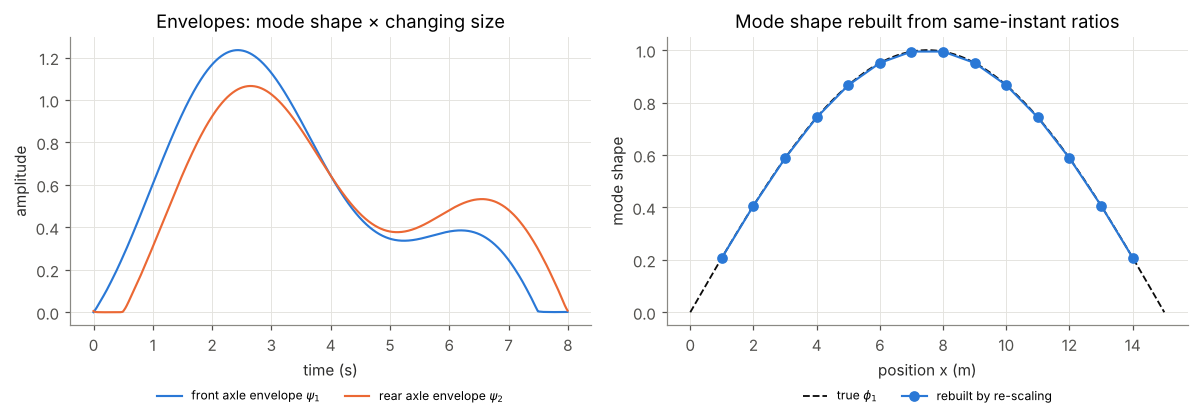

Max error of the rebuilt shape: 0.000


In [3]:
AXLE_SPACING = 1.0                                  # distance between axles (m)
t_axles = np.arange(0, (L_SPAN + AXLE_SPACING) / V_SPEED, 1 / FS)
x_front = V_SPEED * t_axles                         # front axle position (m)
x_rear = x_front - AXLE_SPACING                     # rear axle position (m)

# Modal coordinate with a size that changes in time (unknown to the method)
size = 1 + 0.6 * np.sin(2 * np.pi * 0.15 * t_axles)
q_axles = size * np.cos(2 * np.pi * F1 * t_axles)


def axle_signal(x_axle):
    # Response seen by an axle: phi(x_axle) * q(t), zero when off the bridge
    on_bridge = (x_axle >= 0) & (x_axle <= L_SPAN)
    return np.where(on_bridge, np.sin(np.pi * x_axle / L_SPAN), 0.0) * q_axles


env_front = np.abs(hilbert(axle_signal(x_front)))   # psi_1: front axle envelope
env_rear = np.abs(hilbert(axle_signal(x_rear)))     # psi_2: rear axle envelope

# Re-scaling: points every 1 m, starting at x = 1 m with phi = 1 (arbitrary scale)
x_points = np.arange(1.0, L_SPAN, AXLE_SPACING)     # 1, 2, ..., 14 m
phi_rebuilt = [1.0]
for x_k in x_points[:-1]:
    i = np.argmin(np.abs(x_rear - x_k))             # instant when rear axle is at x_k
    phi_rebuilt.append(phi_rebuilt[-1] * env_front[i] / env_rear[i])
phi_rebuilt = np.array(phi_rebuilt)

phi_true_points = np.sin(np.pi * x_points / L_SPAN)
phi_rebuilt *= phi_true_points.max() / phi_rebuilt.max()   # same scale for comparison

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(t_axles, env_front, color=COLOR_1, label=r"front axle envelope $\psi_1$")
ax.plot(t_axles, env_rear, color=COLOR_2, label=r"rear axle envelope $\psi_2$")
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Envelopes: mode shape × changing size")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)

ax = axes[1]
ax.plot(x_grid, shape_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true $\phi_1$")
ax.plot(x_points, phi_rebuilt, "o-", ms=6, color=COLOR_1, label="rebuilt by re-scaling")
ax.set_xlabel("position x (m)")
ax.set_ylabel("mode shape")
ax.set_title("Mode shape rebuilt from same-instant ratios")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

print(f"Max error of the rebuilt shape: {np.max(np.abs(phi_rebuilt - phi_true_points)):.3f}")

**Interpretación.** Por separado, las envolventes de los dos ejes (izquierda) no se parecen a la forma modal: suben y bajan con el tamaño $q(t)$, que cambia en el tiempo. Pero dividiendo las dos envolventes **en el mismo instante** y encadenando las relaciones cada 1 m, la forma reconstruida coincide con la real (derecha; error máximo < 0.001), sin conocer $q(t)$. La escala global queda indeterminada (se arranca con $\phi = 1$ en 1 m), así que para compararla se normaliza al máximo de la forma real. En este ejemplo ideal no hay ruido ni otros modos; con señales reales cada relación tiene un pequeño error y, como se encadenan, los errores se acumulan a lo largo del puente.

### Con varios modos la proporción ya no es constante

Si vibran a la vez el modo 1 (5.65 Hz) y el modo 2 (22.62 Hz, $\sin(2\pi x/L)$), la señal en cada punto es la suma de los dos. Se comparan dos puntos ($x$ = 3 m y 6 m) y su proporción en el tiempo.

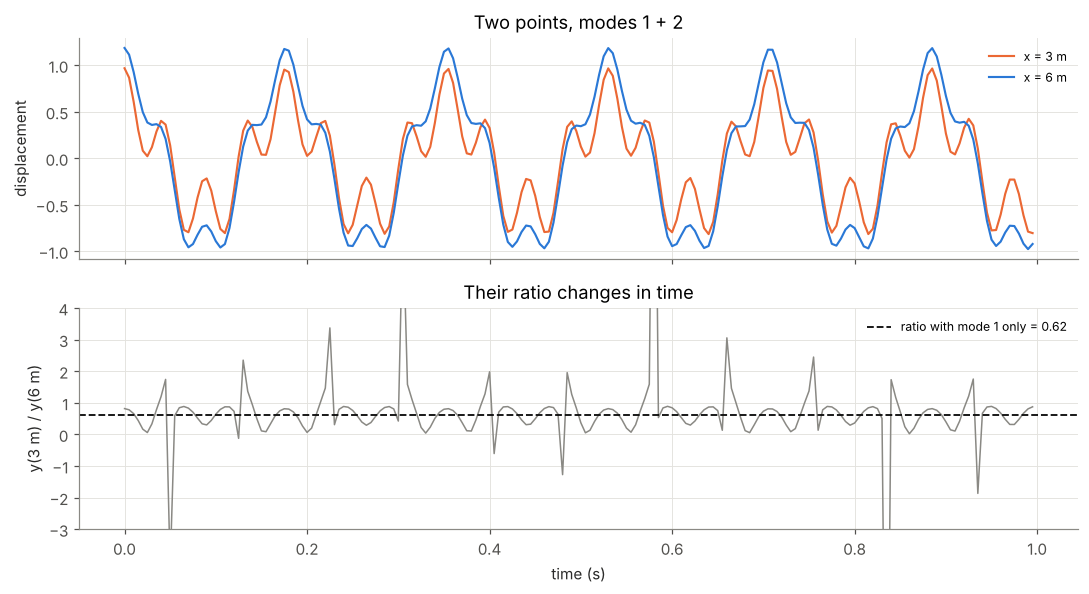

In [4]:
t_two = np.arange(0, 1, 1 / FS)
x_c, x_d = 3.0, 6.0


def two_mode_response(x):
    # Mode 1 + mode 2 (amplitude 0.4), each at its own frequency
    return (np.sin(np.pi * x / L_SPAN) * np.cos(2 * np.pi * F1 * t_two)
            + 0.4 * np.sin(2 * np.pi * x / L_SPAN) * np.cos(2 * np.pi * F2 * t_two))


y_c, y_d = two_mode_response(x_c), two_mode_response(x_d)
ratio_mode_1 = np.sin(np.pi * x_c / L_SPAN) / np.sin(np.pi * x_d / L_SPAN)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(t_two, y_c, color=COLOR_2, label=f"x = {x_c:g} m")
axes[0].plot(t_two, y_d, color=COLOR_1, label=f"x = {x_d:g} m")
axes[0].set_ylabel("displacement")
axes[0].set_title("Two points, modes 1 + 2")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t_two, y_c / y_d, color=COLOR_SIGNAL, linewidth=1)
axes[1].axhline(ratio_mode_1, linestyle="--", color=COLOR_TRUE, linewidth=1.2,
                label=f"ratio with mode 1 only = {ratio_mode_1:.2f}")
axes[1].set_ylim(-3, 4)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel(f"y({x_c:g} m) / y({x_d:g} m)")
axes[1].set_title("Their ratio changes in time")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Cada modo vibra a su propia frecuencia, así que los dos puntos ya no pasan por cero al mismo tiempo y su proporción cambia en cada instante (y salta cuando el denominador pasa por cero): ya no es la forma de ningún modo. Por eso los métodos necesitan **aislar un modo**: con un excitador en resonancia, con un filtro pasabanda o con la EMD ([sección 1.1](#emd)).

<div style="border: 2px solid #2a78d6; border-radius: 6px; padding: 10px 14px; margin: 8px 0;">

📌 **Resumen**

1. **La forma es fija y el tamaño varía:** $y(x,t) = \phi(x)\,q(t)$.
2. **La proporción entre puntos es la forma:** dividiendo mediciones del mismo instante, el tamaño se cancela.
3. **Para usarla hay que tener un solo modo dominante:** con varios modos la proporción cambia en el tiempo.
</div>

<a id="descomposicion-de-senales"></a>
# 1. Descomposición de señales

Métodos que separan una señal en componentes más simples, para analizar cada una por separado.

<a id="emd"></a>
## 1.1 EMD (Empirical Mode Decomposition)

### Para qué sirve

Una señal real de un puente mezcla varias frecuencias: varios modos, el vehículo, la rugosidad y el ruido. La EMD la separa en componentes más simples llamadas **IMF** (funciones de modo intrínseco), cada una con aproximadamente **una sola frecuencia dominante**. Es el paso previo para aplicar la transformada de Hilbert ([sección 2.1](#transformada-de-hilbert)), que necesita una sola componente.

### Cómo funciona (sifting)

La EMD extrae las IMF con un proceso llamado **cribado** (*sifting*):

1. Se ubican los máximos locales y se unen con una curva suave (spline cúbico); lo mismo con los mínimos.
2. Se calcula el promedio de las dos envolventes y se le resta a la señal.
3. Se repite hasta que lo que queda oscila de forma pareja alrededor de cero: esa es la primera IMF, la de frecuencia más alta.
4. Se resta esa IMF de la señal y se repite para obtener la siguiente, de frecuencia más baja, hasta que queda un residuo sin oscilaciones.

$$
m(t) = \frac{e_{max}(t) + e_{min}(t)}{2}, \qquad h(t) = x(t) - m(t)
$$

- $x(t)$: señal.
- $e_{max}(t)$ y $e_{min}(t)$: curvas que unen los máximos y los mínimos.
- $m(t)$: su promedio.
- $h(t)$: señal sin ese promedio, candidata a IMF.

En palabras: se le quita a la señal la "línea media" entre sus picos superiores e inferiores.

$$
x(t) = \sum_{i=1}^{n} c_i(t) + r_n(t)
$$

- $c_i(t)$: IMF número $i$.
- $n$: número de IMF.
- $r_n(t)$: residuo.

En palabras: la señal original es la suma de todas las IMF más el residuo.

Se llama **"empírica"** porque no supone funciones base, como los senos de Fourier: las componentes salen de la forma de la propia señal.

Gráfica: un paso del cribado sobre la señal de puente del ejemplo siguiente (modo 1 + modo 2 + ruido pequeño).

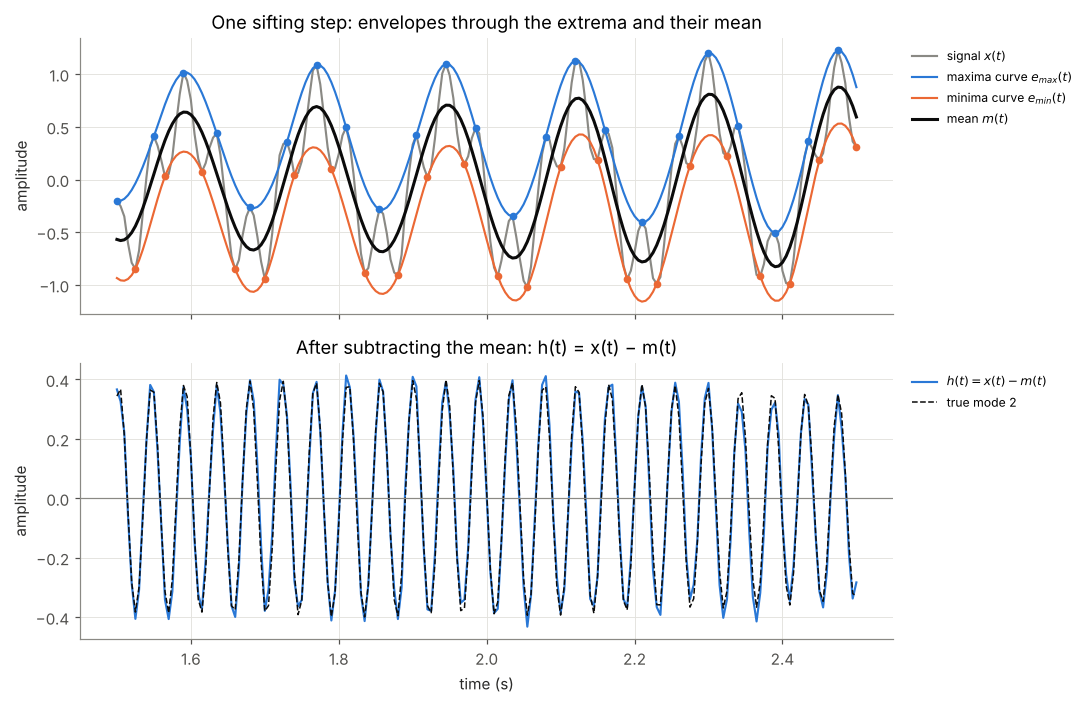

In [5]:
rng = np.random.default_rng(42)   # fixed seed for the noise

# Bridge signal: mode 1 + mode 2 + small noise (also used in the next step)
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.02 * rng.standard_normal(t.size))

# One sifting step: cubic-spline envelopes through the extrema and their mean
idx_max = argrelextrema(x_bridge, np.greater)[0]
idx_min = argrelextrema(x_bridge, np.less)[0]
upper_envelope = CubicSpline(t[idx_max], x_bridge[idx_max])(t)
lower_envelope = CubicSpline(t[idx_min], x_bridge[idx_min])(t)
mean_envelope = (upper_envelope + lower_envelope) / 2      # m(t)

window = (t >= 1.5) & (t <= 2.5)   # zoom into ~1 s where both modes are strong
in_window = lambda idx: idx[window[idx]]

h = x_bridge - mean_envelope                                  # h(t) = x(t) - m(t)
true_mode_2 = 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)        # for comparison

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

ax = axes[0]
ax.plot(t[window], x_bridge[window], color=COLOR_SIGNAL, label="signal $x(t)$")
ax.plot(t[window], upper_envelope[window], color=COLOR_1, label="maxima curve $e_{max}(t)$")
ax.plot(t[window], lower_envelope[window], color=COLOR_2, label="minima curve $e_{min}(t)$")
ax.plot(t[window], mean_envelope[window], color=COLOR_TRUE, linewidth=2, label="mean $m(t)$")
ax.plot(t[in_window(idx_max)], x_bridge[in_window(idx_max)], "o", ms=4, color=COLOR_1)
ax.plot(t[in_window(idx_min)], x_bridge[in_window(idx_min)], "o", ms=4, color=COLOR_2)
ax.set_ylabel("amplitude")
ax.set_title("One sifting step: envelopes through the extrema and their mean")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

ax = axes[1]
ax.plot(t[window], h[window], color=COLOR_1, label="$h(t) = x(t) - m(t)$")
ax.plot(t[window], true_mode_2[window], "--", color=COLOR_TRUE, linewidth=1, label="true mode 2")
ax.axhline(0, color=COLOR_SIGNAL, linewidth=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("After subtracting the mean: h(t) = x(t) − m(t)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

fig.tight_layout()
plt.show()

**Interpretación.** Arriba, la media $m(t)$ (negra) sigue la oscilación lenta, que es el modo 1 (5.65 Hz): las oscilaciones rápidas quedan centradas entre la curva de máximos y la de mínimos, así que al promediarlas se cancelan y solo queda el "centro" que se mueve lento. Abajo, al restar ese centro, $h(t)$ conserva solo la oscilación rápida (modo 2) alrededor de cero, y se parece al modo 2 real. Por eso la primera IMF es la de frecuencia más alta. Este es un solo paso; la EMD lo repite hasta que $h(t)$ cumple las condiciones de IMF.

### Ejemplo: descomponer una señal de puente

Un vehículo cruza un puente de $L = 15$ m a $v = 2$ m/s ($x = vt$). La señal es modo 1, $\sin(\pi x/L)\cos(2\pi f_1 t)$, más modo 2, $0.4\sin(2\pi x/L)\cos(2\pi f_2 t)$, más ruido pequeño. Se aplica la EMD completa con PyEMD.

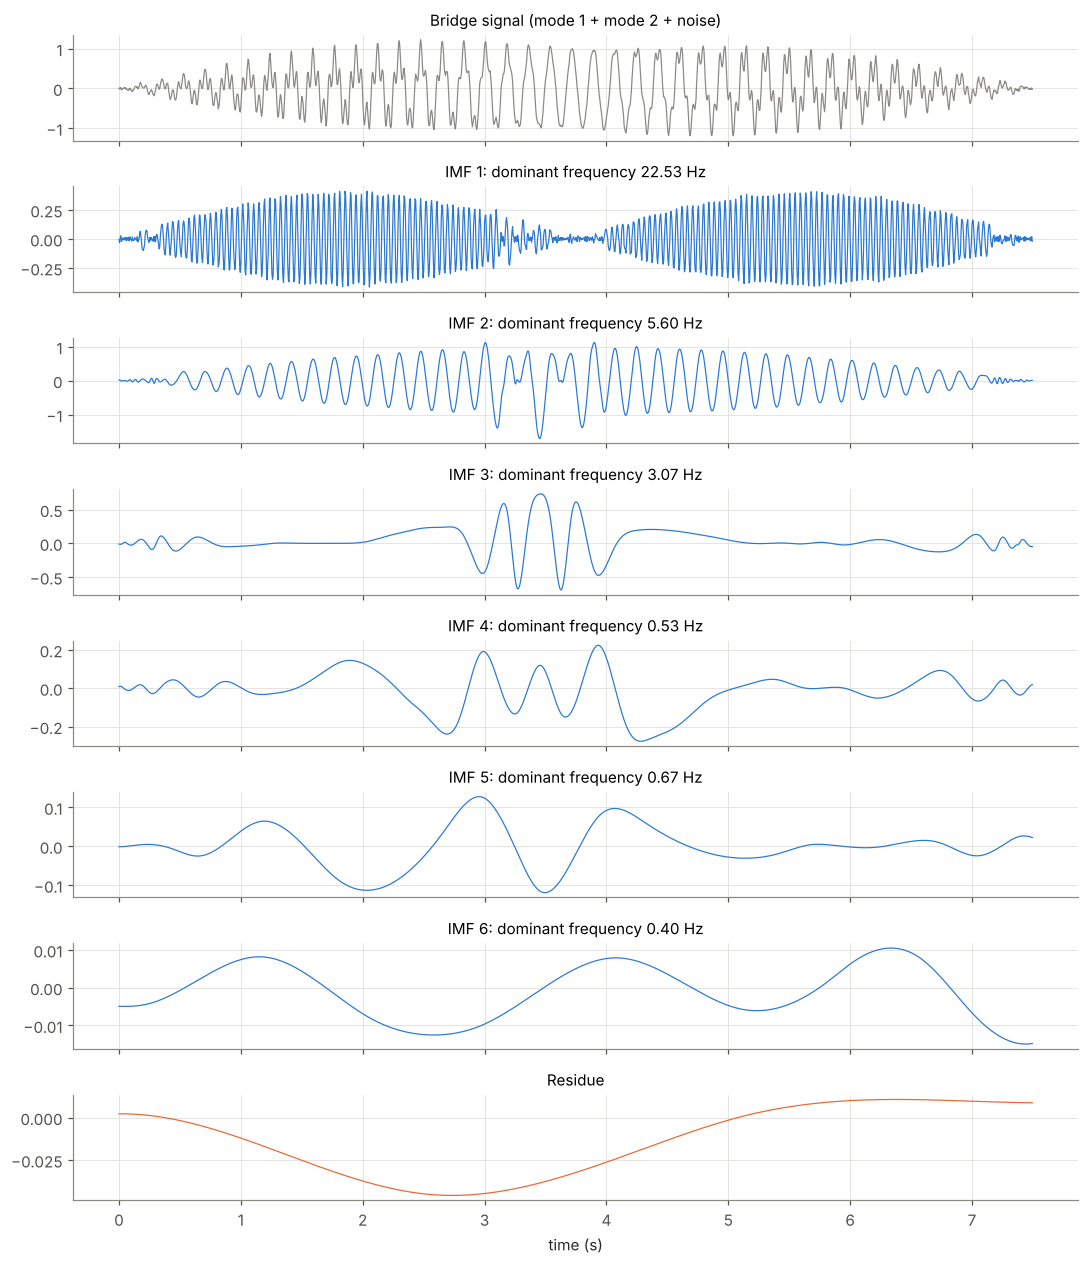

Max reconstruction error |x - (sum of IMFs + residue)|: 0.0e+00


In [6]:
def dominant_frequency(x, fs):
    # Frequency of the largest FFT peak (ignoring 0 Hz)
    spectrum = np.abs(np.fft.rfft(x - x.mean()))
    freqs = np.fft.rfftfreq(x.size, 1 / fs)
    return freqs[np.argmax(spectrum[1:]) + 1]


emd = EMD()
emd.emd(x_bridge, t)
imfs, residue = emd.get_imfs_and_residue()

n_rows = imfs.shape[0] + 2
fig, axes = plt.subplots(n_rows, 1, figsize=(10, 1.45 * n_rows), sharex=True)
axes[0].plot(t, x_bridge, color=COLOR_SIGNAL, linewidth=0.8)
axes[0].set_title("Bridge signal (mode 1 + mode 2 + noise)", fontsize=10)
for i, imf in enumerate(imfs):
    axes[i + 1].plot(t, imf, color=COLOR_1, linewidth=0.8)
    axes[i + 1].set_title(f"IMF {i + 1}: dominant frequency {dominant_frequency(imf, FS):.2f} Hz",
                          fontsize=10)
axes[-1].plot(t, residue, color=COLOR_2, linewidth=0.8)
axes[-1].set_title("Residue", fontsize=10)
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

print(f"Max reconstruction error |x - (sum of IMFs + residue)|: "
      f"{np.max(np.abs(x_bridge - imfs.sum(axis=0) - residue)):.1e}")

**Interpretación.**

- **IMF 1 (≈22.6 Hz) = modo 2:** su amplitud dibuja las dos "jorobas" de $\sin(2\pi x/L)$ y se anula a mitad del vano (nodo); ahí y cerca de los apoyos solo queda el ruido.
- **IMF 2 (≈5.6 Hz) = modo 1:** su amplitud crece y decrece como $\sin(\pi x/L)$.
- Cerca de $t \approx 3.75$ s (mitad del vano), donde el modo 2 desaparece, la IMF 2 se distorsiona y parte del modo 1 se pasa a las IMF 3 y 4: es **mezcla de modos por intermitencia** (una componente que aparece y desaparece), la limitación del paso siguiente.
- Las IMF restantes y el residuo tienen muy poca energía. La suma de todas las IMF más el residuo reproduce la señal exactamente (error impreso arriba).

### Limitación principal: mezcla de modos

Si dos frecuencias están cerca, pueden quedar en la **misma IMF**, o una misma frecuencia puede quedar repartida en varias. Comparación: 5.65 Hz + 22.62 Hz (bien separadas) frente a 5.65 Hz + 7.5 Hz (cercanas), sin ruido.

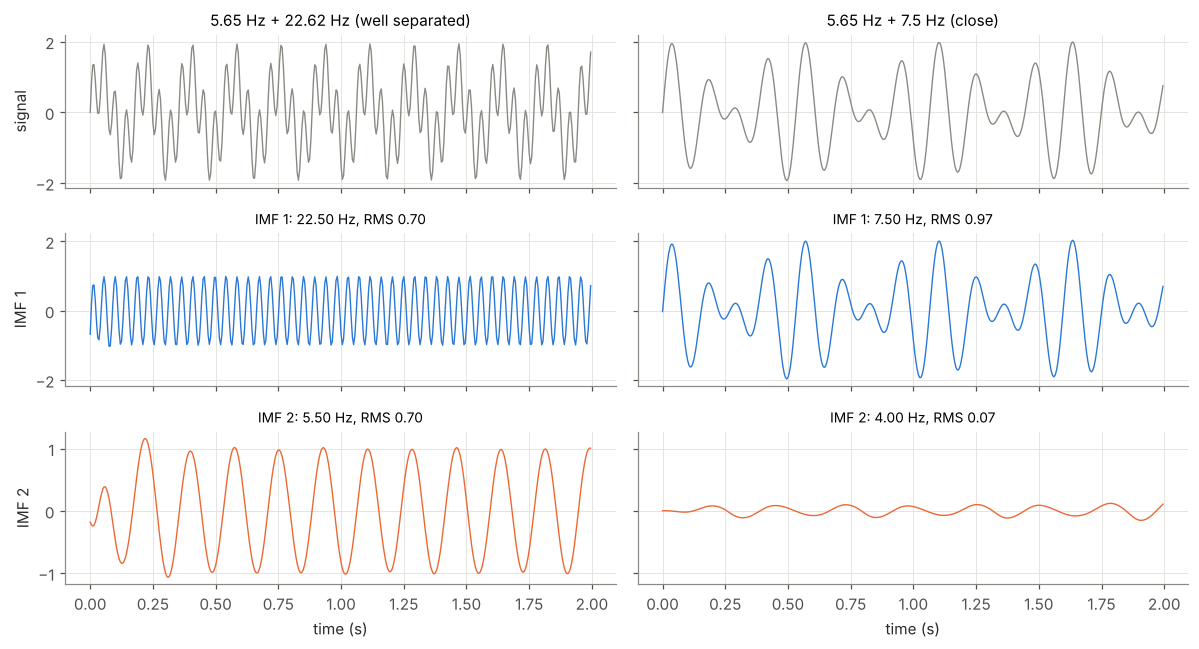

In [7]:
t_short = np.arange(0, 2, 1 / FS)   # 2 s, no noise
cases = {
    "5.65 Hz + 22.62 Hz (well separated)": (F1, F2),
    "5.65 Hz + 7.5 Hz (close)": (F1, 7.5),
}

fig, axes = plt.subplots(3, 2, figsize=(11, 6), sharex=True, sharey="row")
for col, (title, (fa, fb)) in enumerate(cases.items()):
    x_case = np.sin(2 * np.pi * fa * t_short) + np.sin(2 * np.pi * fb * t_short)
    emd_case = EMD()
    emd_case.emd(x_case, t_short)
    imfs_case, _ = emd_case.get_imfs_and_residue()
    axes[0, col].plot(t_short, x_case, color=COLOR_SIGNAL, linewidth=0.9)
    axes[0, col].set_title(title, fontsize=10)
    for row in (1, 2):
        imf = imfs_case[row - 1]
        axes[row, col].plot(t_short, imf, color=COLOR_1 if row == 1 else COLOR_2, linewidth=0.9)
        axes[row, col].set_title(f"IMF {row}: {dominant_frequency(imf, FS):.2f} Hz, "
                                 f"RMS {np.sqrt(np.mean(imf**2)):.2f}", fontsize=9)
for col in (0, 1):
    axes[2, col].set_xlabel("time (s)")
for row, label in enumerate(["signal", "IMF 1", "IMF 2"]):
    axes[row, 0].set_ylabel(label)
fig.tight_layout()
plt.show()

**Interpretación.** Con 5.65 y 22.62 Hz (izquierda) cada frecuencia queda en su propia IMF, con la misma energía (RMS 0.70 cada una). Con 5.65 y 7.5 Hz (derecha) la IMF 1 es prácticamente toda la señal, con batido (RMS 0.97), y la IMF 2 casi no tiene energía (RMS 0.07): la EMD no separó las dos frecuencias.

Variantes que lo mitigan: **EEMD** y **CEEMDAN**, que agregan ruido controlado a la señal, la descomponen muchas veces y promedian; y la **VMD** (*Variational Mode Decomposition*), que descompone de otra forma (resuelve un problema de optimización para encontrar modos de banda estrecha).

### Resumen

| Fortalezas | Debilidades |
|---|---|
| Adaptativa: no necesita elegir una base | Mezcla de modos con frecuencias cercanas |
| Sirve para señales que cambian en el tiempo | Efectos de borde |
| No requiere conocer las frecuencias de antemano (a diferencia del filtro pasabanda) | Sensible al ruido |
| | Sin fundamento matemático cerrado (es un algoritmo) |

**Relación y literatura:** EMD + transformada de Hilbert = **transformada de Hilbert-Huang (HHT)**. Malekjafarian y OBrien (2017) la usan para aislar la componente del modo antes de aplicar Hilbert ([sección 2.1](#transformada-de-hilbert)).

<a id="envolvente-de-amplitud"></a>
# 2. Envolvente de amplitud / amplitud instantánea

Métodos que calculan, en cada instante, la amplitud de una oscilación (su envolvente), sin las subidas y bajadas propias de cada ciclo.

<a id="transformada-de-hilbert"></a>
## 2.1 Transformada de Hilbert

### Para qué sirve

La transformada de Hilbert da la **amplitud de una vibración en cada instante** (la envolvente). La FFT no lo hace, porque promedia todo el registro: dice qué frecuencias hay, pero no cómo cambia su amplitud en el tiempo. En puentes interesa porque, cuando un vehículo cruza, la amplitud del modo cambia con la posición del vehículo, y esa variación refleja la **forma modal**.

### La idea: copia desfasada 90° y envolvente

La transformada genera una **copia de la señal desfasada 90°**, $\mathcal{H}[x(t)]$. Donde una de las dos pasa por cero, la otra está en su máximo, así que juntas siempre "ven" la amplitud. Combinándolas sale la envolvente:

$$
A(t) = \sqrt{x(t)^2 + \mathcal{H}[x(t)]^2}
$$

- $A(t)$: amplitud instantánea o envolvente.
- $x(t)$: señal medida.
- $\mathcal{H}[x(t)]$: transformada de Hilbert, la señal desfasada 90°.

En palabras: la raíz de la señal al cuadrado más su versión desfasada al cuadrado. Por ejemplo, para $x = a\cos(\omega t)$ la copia es $a\sin(\omega t)$ y $A = \sqrt{a^2\cos^2 + a^2\sin^2} = a$.

Ejemplo: un vehículo cruza un puente de $L = 15$ m a $v = 2$ m/s; la componente del modo 1 ($f_1 = 5.65$ Hz) es $x(t) = \sin(\pi v t / L)\cos(2\pi f_1 t)$, muestreada a $f_s = 200$ Hz.

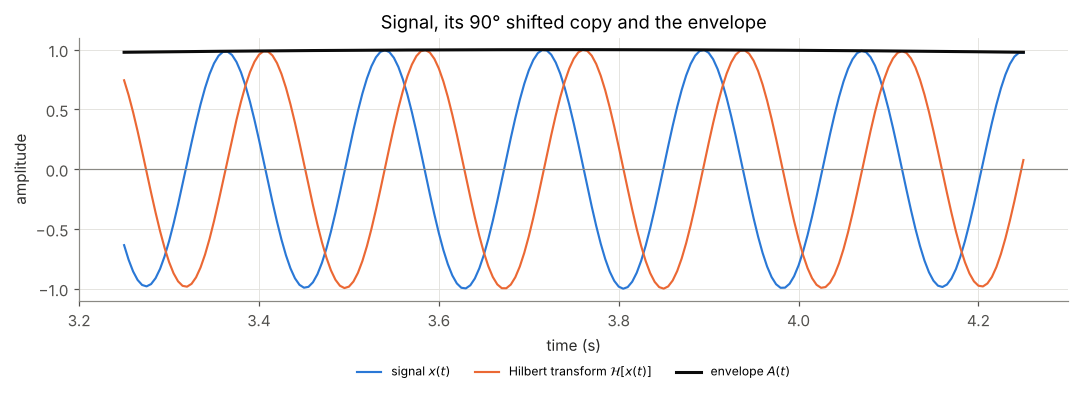

In [8]:
# Mode 1 component of the crossing (shared parameters from the setup cell)
x_ideal = phi_1 * np.cos(2 * np.pi * F1 * t)

z = hilbert(x_ideal)              # analytic signal x + j H[x]
hilbert_x = np.imag(z)            # H[x(t)], the 90° shifted copy
envelope_ideal = np.abs(z)        # A(t) = sqrt(x^2 + H[x]^2)

window = (t >= 3.25) & (t <= 4.25)  # zoom into ~1 s around midspan
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t[window], x_ideal[window], color=COLOR_1, label="signal $x(t)$")
ax.plot(t[window], hilbert_x[window], color=COLOR_2, label=r"Hilbert transform $\mathcal{H}[x(t)]$")
ax.plot(t[window], envelope_ideal[window], color=COLOR_TRUE, linewidth=2, label="envelope $A(t)$")
ax.axhline(0, color=COLOR_SIGNAL, linewidth=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Signal, its 90° shifted copy and the envelope")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Donde la señal azul cruza el cero, la naranja está en un pico, y viceversa. La envolvente (negra) pasa por encima de ambas sin oscilar: es la amplitud en cada instante.

### Requisito: una sola componente

No hace falta una senoidal pura: la amplitud puede variar, siempre que cambie mucho más lento que la oscilación. Pero la señal debe tener **una sola frecuencia dominante**. Si mezcla varias, la envolvente sale ondulada y no significa nada.

Por eso, antes de aplicar Hilbert:

- se **quita la media** de la señal;
- se **aísla la componente**: con un **filtro pasabanda** (si se conoce la frecuencia) o con una descomposición como la [**EMD**](#emd) ([sección 1.1](#emd); EMD + Hilbert = transformada de Hilbert-Huang, **HHT**).

Ejemplo: señal con el modo 1 (5.65 Hz), el modo 2 (22.62 Hz, forma $\sin(2\pi x/L)$, menor amplitud) y ruido.

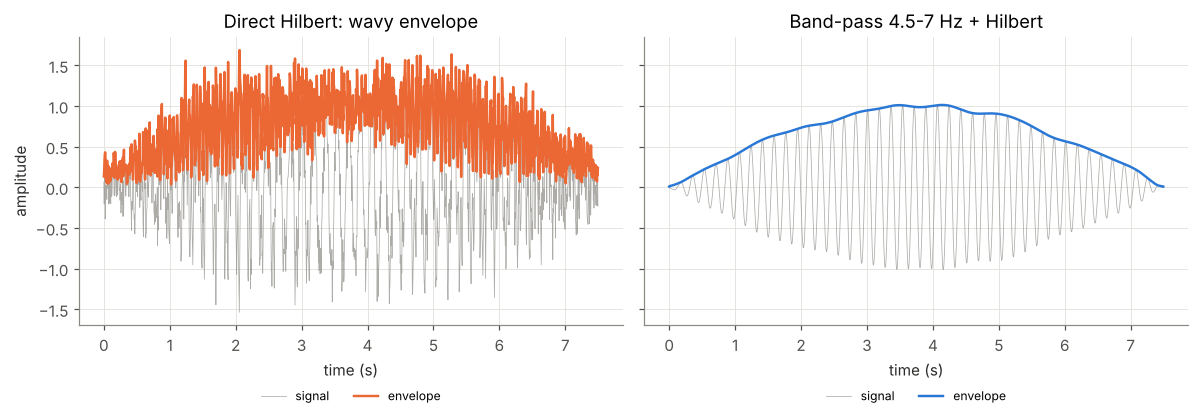

In [9]:
rng = np.random.default_rng(42)   # fixed seed for the noise

x_mode_2 = 0.5 * phi_2 * np.cos(2 * np.pi * F2 * t)
noise = 0.2 * rng.standard_normal(t.size)
x_measured = x_ideal + x_mode_2 + noise
x_measured = x_measured - x_measured.mean()   # remove the mean

# (a) Hilbert applied directly
envelope_direct = np.abs(hilbert(x_measured))

# (b) Band-pass 4.5-7 Hz (4th-order Butterworth, zero phase), then Hilbert
sos = butter(4, [4.5, 7.0], btype="band", fs=FS, output="sos")
x_filtered = sosfiltfilt(sos, x_measured)
envelope_filtered = np.abs(hilbert(x_filtered))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, x, env, color, title in [
    (axes[0], x_measured, envelope_direct, COLOR_2, "Direct Hilbert: wavy envelope"),
    (axes[1], x_filtered, envelope_filtered, COLOR_1, "Band-pass 4.5-7 Hz + Hilbert"),
]:
    ax.plot(t, x, color=COLOR_SIGNAL, linewidth=0.5, alpha=0.7, label="signal")
    ax.plot(t, env, color=color, linewidth=1.6, label="envelope")
    ax.set_title(title)
    ax.set_xlabel("time (s)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
axes[0].set_ylabel("amplitude")
fig.tight_layout()
plt.show()

**Interpretación.** Aplicada directo, la envolvente sube y baja rápido: el modo 2 y el ruido se suman y se restan con el modo 1, y la curva no representa nada físico. Después del pasabanda queda solo el modo 1 y la envolvente es suave.

### Aplicación a puentes

Al graficar la envolvente contra la **posición del vehículo** ($x = vt$) se obtiene la forma del modo. Dos puntos a tener en cuenta:

- La envolvente es el **valor absoluto**, sin signo: en el segundo modo, que es positivo en una mitad del vano y negativo en la otra, daría $|\phi_2|$ y no se distingue qué lado sube y cuál baja.
- Los **extremos se distorsionan** (efecto de borde), por lo que los primeros y últimos ciclos no se interpretan.

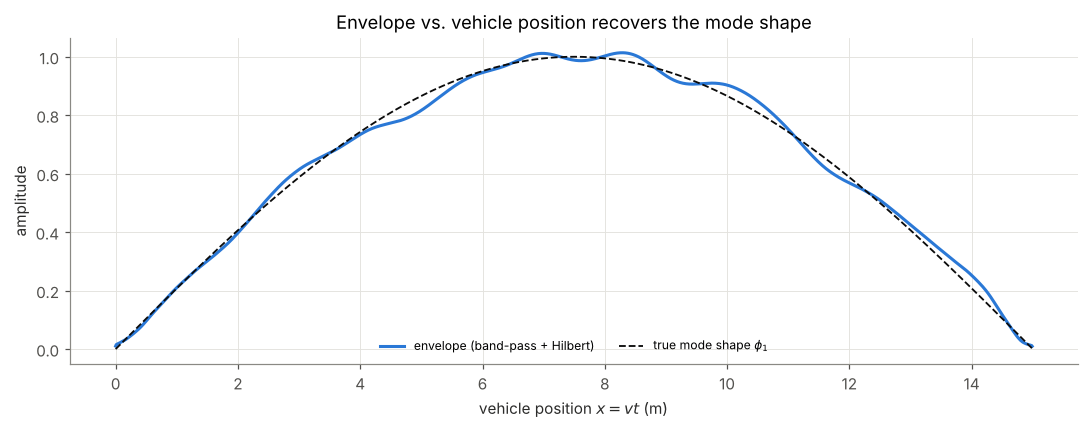

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(position, envelope_filtered, color=COLOR_1, linewidth=2, label="envelope (band-pass + Hilbert)")
ax.plot(position, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true mode shape $\phi_1$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title("Envelope vs. vehicle position recovers the mode shape")
ax.legend(loc="lower center", ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La envolvente sigue la forma modal real; las pequeñas ondulaciones vienen del ruido que cae dentro de la banda del filtro. En este ejemplo los extremos casi no se distorsionan porque la señal empieza y termina con amplitud cero; con señales reales, que no empiezan ni terminan en cero, el efecto de borde sí se nota.

**En la literatura:** Malekjafarian y OBrien (2017) la usan así: aplican la HHT a las aceleraciones de los ejes de un camión con remolques que lleva un excitador, para estimar las formas modales del puente. Su validación es solo en simulación.

### Resumen

| Fortalezas | Debilidades |
|---|---|
| Da la amplitud en cada instante | Exige una sola componente (filtrado o descomposición previa) |
| Sirve para señales que cambian en el tiempo | Sensible al ruido |
| Simple y rápida | Efectos de borde |
| | Pierde el signo de la forma modal |

<a id="sensado-disperso"></a>
# 3. Sensado disperso

Métodos para trabajar con mediciones que solo cubren algunos puntos del puente en cada instante (sensores móviles o escasos), y llevarlas a una malla fija de puntos.

<a id="mapeo-vfp"></a>
## 3.1 Mapeo a puntos fijos virtuales

*Clasificación en la revisión: Sparse sensing / Virtual sensors. Artículo de referencia: Mei et al. (2021), Struct Control Health Monit 28(7):e2747.*

### El problema: los sensores se mueven

La respuesta del puente es $y(x,t) = \sum_k \phi_k(x)\,q_k(t)$ (ver [Fundamentos](#fundamentos)). Si se ordenan las mediciones en una matriz (filas = puntos, columnas = tiempo), esa matriz se puede descomponer en formas $\phi_k$ y coordenadas $q_k$ **solo si cada fila es siempre el mismo punto del puente**. Pero aquí los sensores van en las ruedas del vehículo y se mueven: cada medición corresponde a un punto distinto.

La solución es definir dos tipos de puntos:

- **MMP** (*moving measurement points*, puntos de medición móviles): las **ruedas**, donde sí hay sensor; su posición cambia en el tiempo.
- **VFP** (*virtual fixed points*, puntos fijos virtuales): una malla fija de puntos del puente **sin sensor real**, donde se quiere conocer el desplazamiento. Los VFP de los extremos están sobre los apoyos (desplazamiento cero, conocido).

La idea es estimar, en cada instante, el desplazamiento en los VFP a partir de lo que miden las ruedas.

### Interpolación lineal "al revés"

Si una rueda está en la posición $x$, entre los VFP $s_j$ y $s_{j+1}$, su desplazamiento se escribe como una mezcla lineal de los desplazamientos de esos dos puntos fijos:

$$
y(x) = (1-\alpha)\,d_j + \alpha\,d_{j+1}, \qquad \alpha = \frac{x - s_j}{s_{j+1} - s_j}
$$

- $y(x)$: desplazamiento medido por la rueda en la posición $x$ (dato conocido).
- $s_j$, $s_{j+1}$: posiciones de los dos VFP vecinos, a la izquierda y a la derecha de la rueda.
- $d_j$, $d_{j+1}$: desplazamientos en esos VFP (incógnitas).
- $\alpha$: posición relativa de la rueda dentro del tramo; vale 0 sobre $s_j$ y 1 sobre $s_{j+1}$.

En palabras: la medición de la rueda es un promedio ponderado de los dos puntos fijos que la rodean; pesa más el punto más cercano.

Normalmente la interpolación va de puntos conocidos a un punto intermedio. Aquí va **al revés**: lo conocido es la rueda (el punto intermedio) y lo desconocido son los puntos fijos. Se escribe cada rueda como mezcla de los puntos fijos y luego se **invierte** el sistema para obtener los $d_j$.

**Ejemplo de juguete:** puntos fijos en 0 y 4 m; la rueda A en 1 m mide 3 mm y la rueda B en 3 m mide 5 mm.

In [11]:
# Toy example: two fixed points (0 m and 4 m), two wheels (1 m and 3 m)
s_toy = np.array([0.0, 4.0])                 # virtual fixed points (m)
x_wheels_toy = np.array([1.0, 3.0])          # wheel positions (m)
y_wheels_toy = np.array([3.0, 5.0])          # measured displacements (mm)

alpha_toy = (x_wheels_toy - s_toy[0]) / (s_toy[1] - s_toy[0])
L_toy = np.column_stack([1 - alpha_toy, alpha_toy])   # each row: weights of d1, d2
d_toy = np.linalg.solve(L_toy, y_wheels_toy)

print("Weights matrix L:\n", L_toy)
print(f"d1 = {d_toy[0]:.1f} mm, d2 = {d_toy[1]:.1f} mm")

Weights matrix L:
 [[0.75 0.25]
 [0.25 0.75]]
d1 = 2.0 mm, d2 = 6.0 mm


**Interpretación.** La rueda A da la ecuación $0.75\,d_1 + 0.25\,d_2 = 3$ y la rueda B, $0.25\,d_1 + 0.75\,d_2 = 5$. Dos ecuaciones y dos incógnitas: $d_1 = 2$ mm y $d_2 = 6$ mm. Comprobación: la recta entre (0 m, 2 mm) y (4 m, 6 mm) pasa por 3 mm en 1 m y por 5 mm en 3 m.

### Forma matricial y regla de validez

Con todas las ruedas y todos los VFP a la vez, en cada instante:

$$
\mathbf{Y}(t) = \mathbf{L}(t)\,\mathbf{d}(t) \quad\Rightarrow\quad \hat{\mathbf{d}}(t) = \mathbf{L}(t)^{+}\,\mathbf{Y}(t)
$$

- $\mathbf{Y}(t)$: vector con los desplazamientos medidos por las ruedas que están sobre el puente.
- $\mathbf{L}(t)$: matriz de interpolación, de tamaño (nº de ruedas × nº de VFP); cada fila tiene los pesos $1-\alpha$ y $\alpha$ de una rueda y ceros en el resto. Cambia en cada instante porque las ruedas se mueven.
- $\mathbf{d}(t)$: desplazamientos en los VFP (incógnitas); $\hat{\mathbf{d}}(t)$ es su estimación.
- $\mathbf{L}^{+}$: **pseudoinversa de Moore–Penrose**.

En palabras: como $\mathbf{L}$ casi nunca es cuadrada (hay pocas ruedas y muchos VFP), no se puede invertir directamente; la pseudoinversa da la solución de **mínimos cuadrados** (la que mejor ajusta las mediciones) y, si faltan ecuaciones, la de menor tamaño entre todas las posibles.

**Regla de validez de Mei:** un VFP es válido en un instante si hay **al menos dos ruedas** en total en la región entre su vecino izquierdo y su vecino derecho, $(s_{j-1},\ s_{j+1})$. Los VFP que no cumplen la regla se marcan como **dato faltante**.

> ⚠️ **Caso problemático.** Si las dos ruedas quedan a ambos lados de un punto $s_j$ (una en $[s_{j-1}, s_j]$ y otra en $[s_j, s_{j+1}]$), las ecuaciones involucran **tres incógnitas** ($d_{j-1}$, $d_j$, $d_{j+1}$) con solo **dos ecuaciones**: el sistema es indeterminado y la estimación tiene error (Figura 10 del artículo). Con más ruedas sobre el puente hay más ecuaciones y el error se reduce.

### Simulación: un vehículo cruzando un puente de 40 m

Parámetros (constantes con prefijo `MEI_` para no chocar con las del setup): puente simplemente apoyado de 40 m con frecuencias de 1.44, 5.76 y 12.95 Hz, vehículo a 40 km/h, $f_s$ = 200 Hz, ejes separados 2.5 m y 10 VFP equiespaciados (los dos de los extremos sobre los apoyos).

- **Supuesto propio:** vehículo de **2 ejes** (las instrucciones de esta sección no fijan el número de ejes).
- Modos analíticos $\phi_k(x) = \sin(k\pi x/L)$ y coordenadas modales sintéticas: una vibración $A_k \sin(2\pi f_k t)$ más una respuesta cuasiestática suave (la deflexión que sigue a la carga). Las amplitudes son proporcionales a $1/k^4$, porque la rigidez de un modo crece con $k^4$ y los modos altos aportan mucho menos desplazamiento.
- Se usa el **desplazamiento verdadero** en las ruedas. Mei integra dos veces la aceleración medida para obtenerlo; aquí se omite ese paso para aislar el mapeo.
- La simulación empieza cuando la rueda delantera entra al puente y termina cuando llega al final.

In [12]:
# --- Mei et al. (2021) style simulation ---
MEI_SPAN = 40.0                                  # bridge span (m)
MEI_FREQS = np.array([1.44, 5.76, 12.95])        # natural frequencies (Hz)
MEI_SPEED = 40 / 3.6                             # 40 km/h in m/s
MEI_FS = 200.0                                   # sampling frequency (Hz)
MEI_AXLE_GAP = 2.5                               # distance between axles (m)
MEI_N_AXLES = 2                                  # own assumption: two-axle vehicle
MEI_N_VFP = 10
MEI_VFP = np.linspace(0, MEI_SPAN, MEI_N_VFP)    # virtual fixed points (supports at both ends)

mei_t = np.arange(0, MEI_SPAN / MEI_SPEED, 1 / MEI_FS)   # until the front wheel reaches the end
mei_modes = np.arange(1, len(MEI_FREQS) + 1)
mei_amp = 1.0 / mei_modes**4                              # higher modes contribute less

# Synthetic modal coordinates q_k(t): vibration + smooth quasi-static response (mm)
mei_q = (2.0 * mei_amp[:, None] * np.sin(2 * np.pi * MEI_FREQS[:, None] * mei_t)
         + 8.0 * mei_amp[:, None] * np.sin(mei_modes[:, None] * np.pi * MEI_SPEED * mei_t / MEI_SPAN))


def mei_displacement(x, k_time):
    # True bridge displacement y(x, t) = sum_k phi_k(x) q_k(t) at time index k_time
    phi = np.sin(np.outer(np.atleast_1d(x), mei_modes) * np.pi / MEI_SPAN)
    return phi @ mei_q[:, k_time]


def interpolation_matrix(x_wheels, vfp):
    # Rows: wheels; columns: interior VFPs (supports are known zeros, so they drop out)
    L_mat = np.zeros((len(x_wheels), len(vfp)))
    for i, x in enumerate(x_wheels):
        j = min(np.searchsorted(vfp, x, side="right") - 1, len(vfp) - 2)
        alpha = (x - vfp[j]) / (vfp[j + 1] - vfp[j])
        L_mat[i, j], L_mat[i, j + 1] = 1 - alpha, alpha
    return L_mat[:, 1:-1]


def valid_vfps(x_wheels, vfp):
    # Mei's rule: at least two wheels between the left and right neighbours of each VFP
    valid = np.zeros(len(vfp), dtype=bool)
    for j in range(1, len(vfp) - 1):
        valid[j] = np.sum((x_wheels > vfp[j - 1]) & (x_wheels < vfp[j + 1])) >= 2
    return valid


axle_offsets = np.arange(MEI_N_AXLES) * MEI_AXLE_GAP      # front axle first
n_time = mei_t.size
D_true = np.zeros((MEI_N_VFP, n_time))
D_sparse = np.full((MEI_N_VFP, n_time), np.nan)
mask_valid = np.zeros((MEI_N_VFP, n_time), dtype=bool)
straddle = np.zeros((MEI_N_VFP, n_time), dtype=bool)      # wheels on both sides of the VFP

for k in range(n_time):
    D_true[:, k] = mei_displacement(MEI_VFP, k)
    x_wheels = MEI_SPEED * mei_t[k] - axle_offsets
    x_wheels = x_wheels[(x_wheels >= 0) & (x_wheels <= MEI_SPAN)]   # wheels on the bridge
    D_sparse[[0, -1], k] = 0.0                                       # supports: known zeros
    if x_wheels.size == 0:
        continue
    y_wheels = mei_displacement(x_wheels, k)                         # what the wheels measure
    d_hat = np.linalg.pinv(interpolation_matrix(x_wheels, MEI_VFP)) @ y_wheels
    valid = valid_vfps(x_wheels, MEI_VFP)
    mask_valid[:, k] = valid
    D_sparse[1:-1, k] = np.where(valid[1:-1], d_hat, np.nan)
    for j in np.where(valid)[0]:
        straddle[j, k] = np.any(x_wheels < MEI_VFP[j]) and np.any(x_wheels > MEI_VFP[j])

err = np.abs(D_sparse - D_true) / np.abs(D_true).max()
print(f"Time steps: {n_time}, VFPs: {MEI_N_VFP}")
print(f"Mean error (valid VFPs), both wheels on one side: {np.nanmean(err[mask_valid & ~straddle]):.1%}")
print(f"Mean error (valid VFPs), wheels on both sides:    {np.nanmean(err[mask_valid & straddle]):.1%}")

Time steps: 720, VFPs: 10
Mean error (valid VFPs), both wheels on one side: 0.7%
Mean error (valid VFPs), wheels on both sides:    7.4%


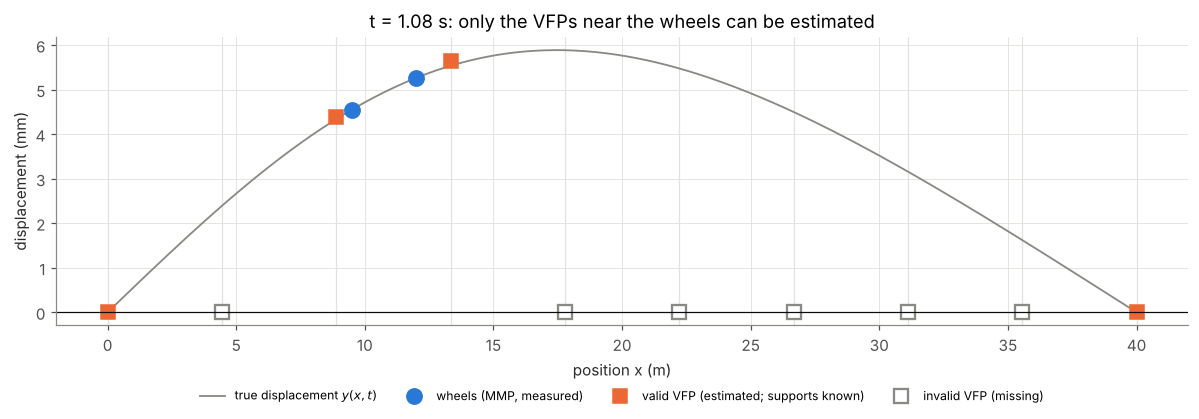

In [13]:
# Plot 1: the beam at one instant (front wheel at 12 m)
k_show = np.argmin(np.abs(MEI_SPEED * mei_t - 12.0))
x_fine_mei = np.linspace(0, MEI_SPAN, 400)
x_wheels_show = MEI_SPEED * mei_t[k_show] - axle_offsets
valid_show = mask_valid[:, k_show].copy()
valid_show[[0, -1]] = True                                  # supports: known

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(x_fine_mei, mei_displacement(x_fine_mei, k_show), color=COLOR_SIGNAL, lw=1.2,
        label="true displacement $y(x,t)$")
ax.plot(x_wheels_show, mei_displacement(x_wheels_show, k_show), "o", ms=10, color=COLOR_1,
        label="wheels (MMP, measured)")
ax.plot(MEI_VFP[valid_show], D_sparse[valid_show, k_show], "s", ms=9, color=COLOR_2,
        label="valid VFP (estimated; supports known)")
ax.plot(MEI_VFP[~valid_show], np.zeros((~valid_show).sum()), "s", ms=9, mfc="white",
        mec=COLOR_SIGNAL, mew=1.5, label="invalid VFP (missing)")
for x in MEI_VFP:
    ax.axvline(x, color="#e3e2de", lw=0.8, zorder=0)
ax.axhline(0, color=COLOR_TRUE, lw=0.8)
ax.set_xlabel("position x (m)")
ax.set_ylabel("displacement (mm)")
ax.set_title(f"t = {mei_t[k_show]:.2f} s: only the VFPs near the wheels can be estimated")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Las dos ruedas (azul) solo "ven" el tramo donde están. Los VFP vecinos a ese tramo cumplen la regla y se estiman (naranja); el resto queda vacío (blanco), aunque el puente también se esté moviendo ahí. Los apoyos se conocen (cero).

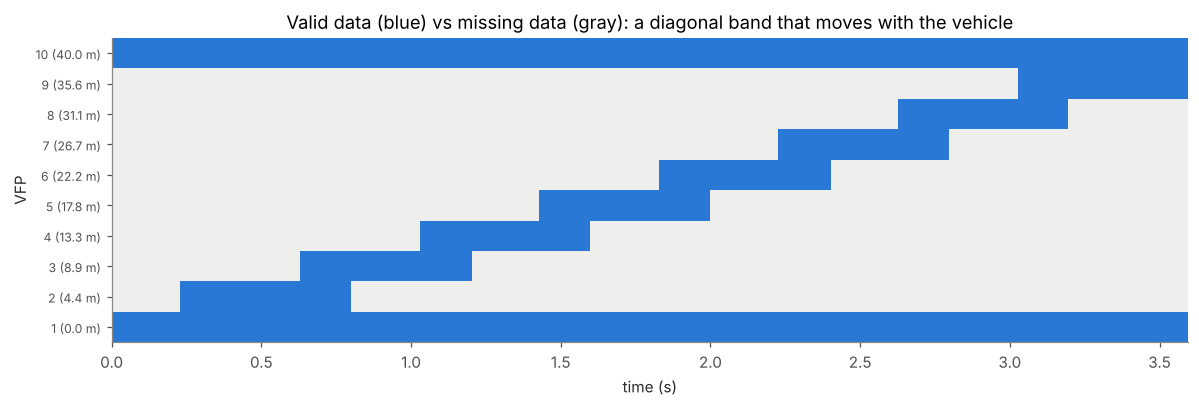

Missing data, full matrix (supports counted as known): 67.31 %
Missing data, interior VFPs only:                      84.13 %
Mei et al. (2021) report: 66.41 %


In [14]:
# Plot 2: validity mask (rows = VFPs, columns = time)
from matplotlib.colors import ListedColormap

mask_plot = mask_valid.copy()
mask_plot[[0, -1], :] = True                                  # supports: known

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.imshow(mask_plot, aspect="auto", origin="lower", interpolation="nearest",
          cmap=ListedColormap(["#eeeeec", COLOR_1]),
          extent=[mei_t[0], mei_t[-1], -0.5, MEI_N_VFP - 0.5])
ax.set_yticks(range(MEI_N_VFP))
ax.set_yticklabels([f"{i + 1} ({x:.1f} m)" for i, x in enumerate(MEI_VFP)], fontsize=8)
ax.set_xlabel("time (s)")
ax.set_ylabel("VFP")
ax.set_title("Valid data (blue) vs missing data (gray): a diagonal band that moves with the vehicle")
ax.grid(False)
fig.tight_layout()
plt.show()

missing_all = 100 * (1 - mask_plot.mean())
missing_interior = 100 * (1 - mask_valid[1:-1].mean())
print(f"Missing data, full matrix (supports counted as known): {missing_all:.2f} %")
print(f"Missing data, interior VFPs only:                      {missing_interior:.2f} %")
print("Mei et al. (2021) report: 66.41 %")

**Interpretación.** Con el vehículo de 2 ejes falta el **67.31 %** de la matriz completa (contando los apoyos como datos conocidos), muy cerca del **66.41 %** que reporta Mei; si solo se cuentan los 8 VFP interiores, falta el 84.13 %. El número de ejes es un supuesto propio y no verifiqué contra el artículo cómo calcula Mei ese porcentaje, así que la coincidencia es indicativa. La simulación también muestra el caso problemático: entre los VFP válidos, el error medio es 0.7 % cuando las dos ruedas están del mismo lado del punto y 7.4 % cuando quedan a ambos lados (relativo al desplazamiento máximo).

El resultado del mapeo **no** es una matriz completa sino una **matriz con huecos**: cada fila ya es un punto fijo del puente (lo que se necesitaba para descomponerla), pero la mayoría de sus valores faltan. Completar esa matriz es el punto de partida de la sección 3.2.

> 📝 **Nota: por qué interpolación lineal.** Oshima et al. (2014) usaban interpolación de Lagrange de orden alto. Al invertirla (pasar de las ruedas a los puntos fijos) el sistema se vuelve inestable: pequeños errores en las mediciones se amplifican. Mei et al. (2021) la reemplazaron por la interpolación lineal; según reportan, con Lagrange el MAC del tercer modo cae a 0.676.

### Resumen

| Fortalezas | Debilidades |
|---|---|
| Convierte mediciones móviles en filas fijas, que sí se pueden descomponer | Deja la mayoría de los datos faltantes (≈2/3 en Mei) |
| Simple: interpolación lineal y pseudoinversa | Error cuando las ruedas quedan a ambos lados de un punto (sistema indeterminado) |
| Estable al invertir, a diferencia de Lagrange de orden alto | Requiere conocer la posición de cada rueda y obtener el desplazamiento (doble integración de la aceleración) |